**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

This notebook takes the beta diveristy trajectories, converts them to periods to reflect the difference potential recovery profiles, ...

In [1]:
import itertools as it
import re
import os
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import numpy as np
import pandas as pd
import scipy
from scipy.stats import studentized_range as q_dist
import seaborn as sn
import skbio
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.longitudinal.actions as q2_longitudinal

from scripts.extract_fits import (extract_period_fits,
                                  extract_abxbl_fit,
                                  build_tidy_str,
                                  find_abx,
                                 )
import scripts.alpha_plots as ap

from IPython.display import HTML

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
hide_axes = dict(left=False, labelleft=False,
                 right=False, labelright=False,
                 length=0,
                 labelsize=0)

In [3]:
%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)


In [4]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}
abx_colors2 = {i: color for i, color in enumerate(colors)}

In [5]:
clean_metrics = {'observed_features': 'Observed Species',
                 'unweighted_unifrac': 'unweighted\nUniFrac',
                 'weighted_unifrac': 'weighted\nUniFrac',
                 'braycurtis': 'Bray Curtis',
                 'rpca': 'rPCA\nAitchison',
                 'phylo_rpca': 'phylo rPCA\nAitchison'
                 }


# Data

## Metadata

In [6]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()

## Alpha Diversity

In [7]:
alpha_dir = 'final-data/04.alpha-diveristy'
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
    for metric in alpha_metrics
    }
meta_a = pd.DataFrame({metric: art.view(pd.Series) 
                       for metric, art in alpha_q2.items()})
meta_a[['host_subject_id', 'timepoint']] = meta[['host_subject_id', 'timepoint']]
meta_a.sort_values(['host_subject_id', 'timepoint'], ascending=True, inplace=True)
meta_a0 = meta_a.groupby('host_subject_id').first()[alpha_metrics]
alpha0 = meta_a0.loc[meta_a['host_subject_id'], alpha_metrics]
alpha0.index = meta_a.index

In [8]:
a_traces_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg_from_baseline.qza')
    for metric in np.hstack([alpha_metrics, 'depth'])
    }
a_traces = pd.DataFrame(
    {metric: art.view(pd.Series) for metric, art in a_traces_q2.items()
     if metric in alpha_metrics}
)

## Beta Diversity

In [9]:
classic_beta_dir = 'final-data/06.beta-diveristy/'
dm_fps = {fp_.split('_1M')[0]: f'{classic_beta_dir}/{fp_}'
          for fp_ in os.listdir(classic_beta_dir) 
          if 'dm.qza' in fp_}

dms_q2 = {metric: Artifact.load(fp_) for metric, fp_ in dm_fps.items()}

In [10]:
trace_kwargs = dict(metadata=Metadata(meta),
                                state_column='timepoint',
                                individual_id_column='host_subject_id',
                                baseline=0)
b_traces_q2 = {
    metric: q2_longitudinal.first_distances(dm_q2, **trace_kwargs).first_distances
    for metric, dm_q2 in dms_q2.items()
}
b_traces = pd.DataFrame({metric: trace_q2.view(pd.Series) 
                         for metric, trace_q2 in b_traces_q2.items()})

## Combined data

In [11]:
meta_t = pd.concat(
    axis=1, 
    objs=[meta,
          a_traces_q2['depth'].view(pd.Series).to_frame().rename(columns={'Difference': 'depth_d'}) / 1e5,
          (a_traces / alpha0 * 100), 
          alpha0.add_suffix('_0'),
          (alpha0 < meta_a0.median()).add_suffix('_0_cat').replace({True: 'lo', False: 'hi'}),
          b_traces,
         ]
    )
meta_t.replace({metric: {np.nan: 0} for metric in alpha_metrics},
              inplace=True)
meta_t.sort_values(['abx_code2', 'host_subject_id', 'timepoint'],
                   ascending=True, inplace=True)
meta_t['first_extraction'] = \
    meta_t['host_subject_id'].replace(meta_t.groupby('host_subject_id')['extraction_no'].first())
meta_t['extr_not0'] = (meta_t['extraction_no'] != meta_t['first_extraction']) * 1
meta_t['days_inv'] = 30 / meta_t['days_since_intervention']
meta_t['abx_code2'] = meta_t['abx_code2'].astype(int)
meta_t['period'] = (meta_t['timepoint'].astype(float) > 0) * 1 + \
    (meta_t['timepoint'].astype(float) > 3) * 1

# Visualization

In [12]:
beta_metrics = ['jaccard','unweighted_unifrac', 
                # 'rpca', 'phylo_rpca', 
                'braycurtis', 'weighted_unifrac']
div_metrics = np.hstack([beta_metrics])

In [13]:
trace_w = meta_t.pivot(index=['abx_code2', 'host_subject_id'],
                       columns='timepoint',
                       values=div_metrics)
trace_w.drop(columns=['0.0'], level='timepoint', inplace=True)
trace_summary = \
    meta_t.groupby(['abx_code2', 'timepoint'])[div_metrics].describe()
trace_summary.drop(index=['0.0'], level='timepoint', inplace=True)
trace_summary.columns.set_names(['metric', 'statistic'], inplace=True)
trace_summary = trace_summary.unstack().unstack().reset_index()
trace_summary.rename(columns={0: 'value'}, inplace=True)
trace_summary['abx_code2'] = trace_summary['abx_code2'].astype(int)
trace_summary = trace_summary.pivot(
    index=['metric', 'abx_code2', 'timepoint'],
    columns='statistic',
    values='value',
    )
trace_summary['t'] = scipy.stats.t.ppf(0.975, df=trace_summary['count'] - 1)
trace_summary['sem'] = trace_summary['std'] / np.sqrt(trace_summary['count'] - 1)
trace_summary['ci'] = trace_summary['sem'] * trace_summary['t']

trace_summary = trace_summary.unstack()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


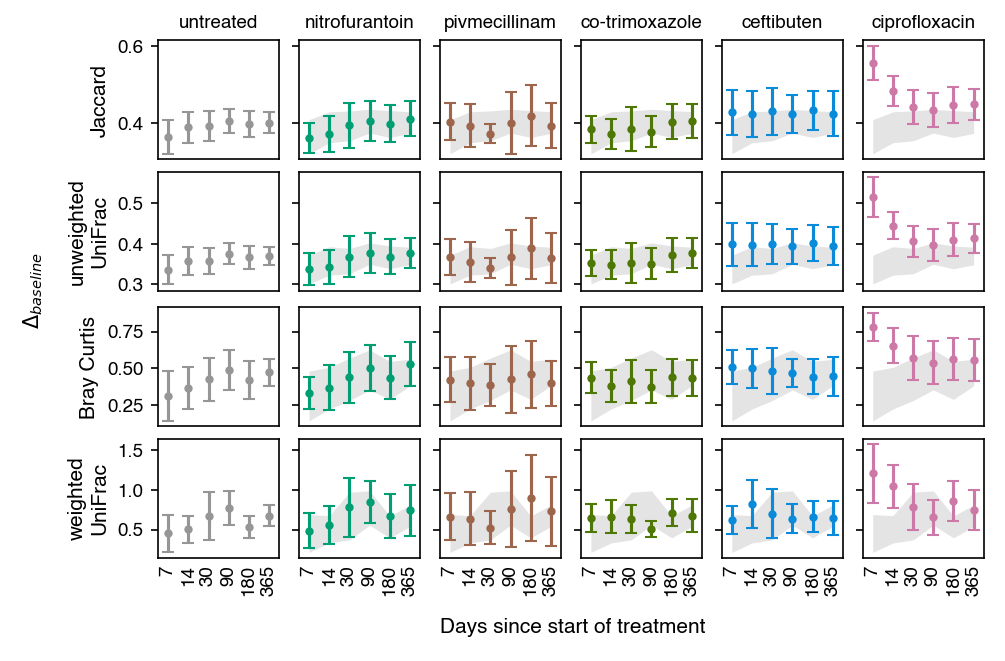

In [14]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6.5, 4.25))
[[figy, figa], [_, figx]] = fig.subfigures(2, 2, 
                                            width_ratios=[0.25, 6.25], 
                                            height_ratios=[4, 0.25],
                                            facecolor='None'
                                            )
gsa = figa.add_gridspec(4, 6)
for row, metric in enumerate(beta_metrics):
    metric_clean = clean_metrics.get(metric, metric.title())
    # metric_clean = metric_clean.replace(' ', '\n')
    df = trace_summary.xs(metric, level='metric')
    for abx, data in df.iterrows():
        if abx == 0:
            axa = figa.add_subplot(gsa[row, abx])
            axa.set_ylabel(metric_clean, size=10)
            axra = axa
        else:
            axa = figa.add_subplot(gsa[row, abx], sharex=axa, sharey=axa)
        ap._plot_forest_square(axa, abx, df, xx=np.arange(6) + 1)
        ap._format_beta_axes(axa, abx, (row == 3), )
        if row == 0:
            axa.set_title(abx_order[abx], size=9)

ap._add_labelfig(figy, '$\\Delta_{baseline}$', 
                  rotation=90, 
                  position=(0.05, 0.1, 0.9, 0.85))
ap._add_labelfig(figx, 'Days since start of treatment', 
                  position=(0.1, 0, 0.90, 1))

fig.savefig('output/figures/figure_s8_beta_traces.png', dpi=600, facecolor='None')
fig.savefig('output/figures/figure_s8_beta_traces.pdf', dpi=600, facecolor='None')

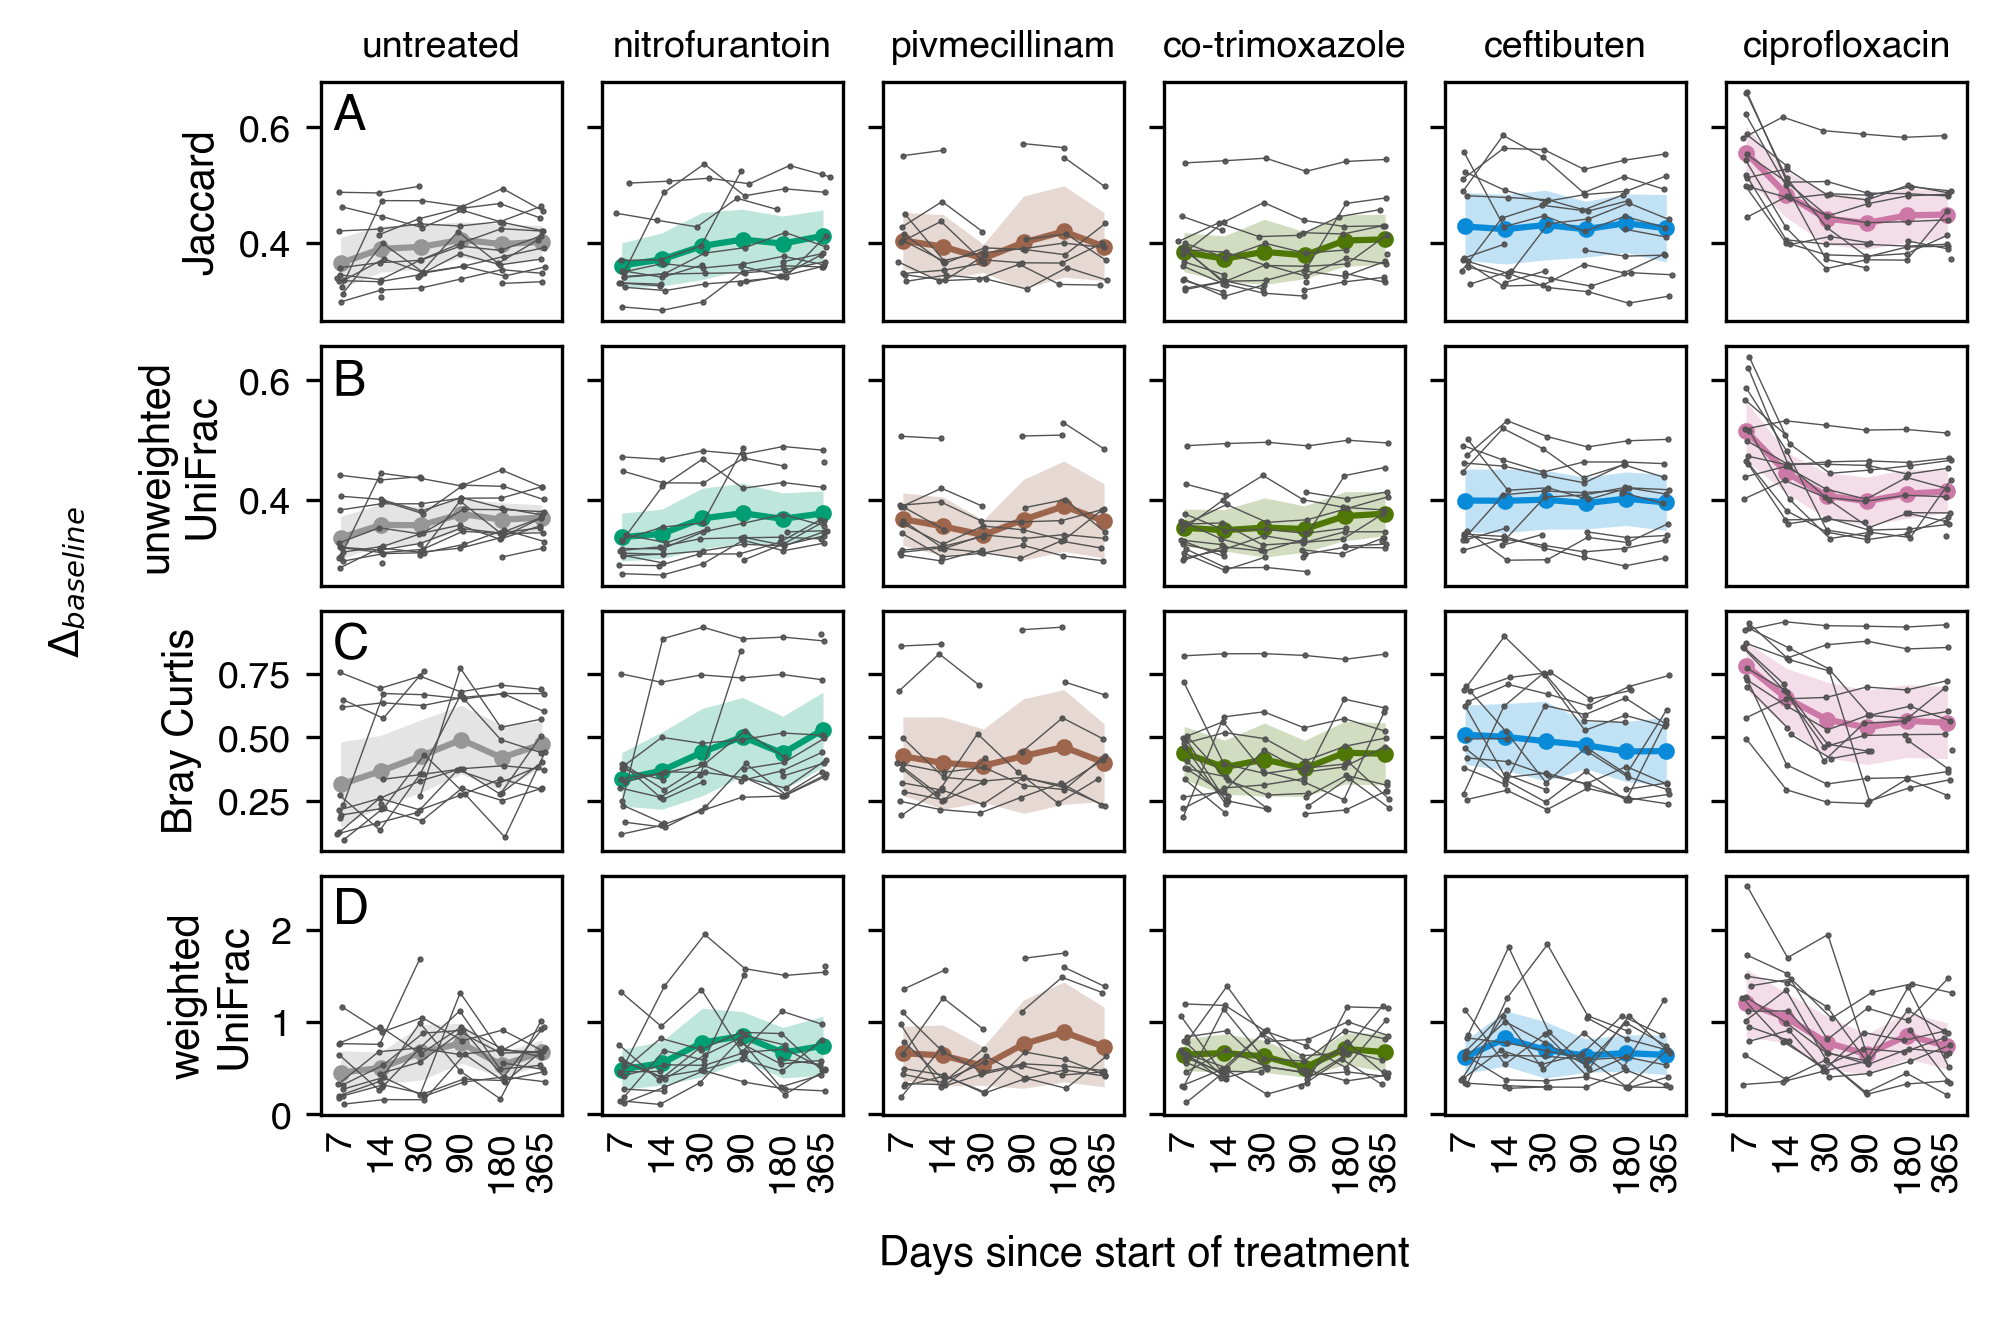

In [15]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(6.5, 4.25))
[[figy, figa], [_, figx]] = fig.subfigures(2, 2, 
                                            width_ratios=[0.25, 6.25], 
                                            height_ratios=[4, 0.25],
                                            facecolor='None'
                                            )
gsa = figa.add_gridspec(4, 6)
for row, metric in enumerate(beta_metrics):
    metric_clean = clean_metrics.get(metric, metric.title())
    msummary_df = trace_summary.xs(metric, level='metric')
    for abx, trace_df in trace_w[metric].groupby('abx_code2'):
        if abx == 0:
            axa = figa.add_subplot(gsa[row, abx])
            axa.set_ylabel(metric_clean, size=10)
            axra = axa
        else:
            axa = figa.add_subplot(gsa[row, abx], sharex=axa, sharey=axa)
        ap._plot_trace_square(axa, abx, msummary_df, trace_df, 
                              xx=np.arange(6) + 1)
        ap._format_beta_axes(axa, abx, (row == 3))
        if row == 0:
            axa.set_title(abx_order[abx], size=9)
    axra.text(axra.get_xlim()[0] + 0.05 * np.diff(axra.get_xlim()),
              axra.get_ylim()[1] - 0.05 * np.diff(axra.get_ylim()),
              'ABCD'[row],
              ha='left',
              va='top', 
              size=12)

ap._add_labelfig(figy, '$\\Delta_{baseline}$', 
                  rotation=90, 
                  position=(0.05, 0.1, 0.9, 0.85))
ap._add_labelfig(figx, 'Days since start of treatment', 
                  position=(0.1, 0, 0.90, 1))

Based on the curves, there appear to be multiple patterns. So, I want to divide the data into periods (early 7-30) and late (90+) recovery to let us model how things change. I realize this is maybe not he best overall approach, but it gets us somewhere?

# Modeling

In [16]:
meta_r = meta_t.loc[~meta_t['timepoint'].isin(['0.0'])].copy()
meta_r['abx_bl'] = (meta_r['abx_code2'] * 10 + meta_r['period'])
for metric in beta_metrics:
    meta_r[f'{metric}_sc'] = meta_r[metric] * 10
meta_r.index.set_names('SampleID', inplace=True)

## Adjustments

In [17]:
ref_eqs = {
    'crude': 'depth_d',
    'model 1': 'depth_d + C(extraction_no)',
    'model 2': ('depth_d + C(extraction_no) + after_travel_na_eu'),
    'model 3': ('depth_d + C(extraction_no) + after_travel_na_eu + age + sex + vegetarian'),
}

## Primary model

In [18]:
fit_untreat = {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric}_sc ~ C(abx_code2)*C(period) + {ref_eq}',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ C(period)'])
    for metric in beta_metrics
    }
fit_unt_i_params = pd.concat(
    axis=0, 
    objs=[extract_period_fits(fit_, *keys)
          for keys, fit_ in fit_untreat.items()]
    )

In [19]:
fit_expand_all =  {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric}_sc ~ C(abx_bl) + {ref_eq} - 1',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ C(period)'])
    for metric in beta_metrics
    }
fit_unt_e_params = pd.concat(
    axis=0,
    objs=[extract_abxbl_fit(fit_, *keys)
          for keys, fit_ in fit_expand_all.items()]
    )

And then I think I want a model by period

In [20]:
period_fits = {
    (metric, model, rs_slope, '0', period): smf.mixedlm(f'{metric}_sc ~ C(abx_code2) + {ref_eq}',
                                                   data=period_df,
                                                   re_formula=re_formula,
                                                   groups='host_subject_id').fit()
    for period, period_df in meta_r.groupby('period')
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ C(period)'])
    for metric in beta_metrics
}
period_params = pd.concat(
    axis=0, 
    objs=[extract_period_fits(fit_, metric, model, rs_slope, ref_value, period=period)
          for (metric, model, rs_slope, ref_value, period), fit_ in period_fits.items()]
)
period_params.set_index(['metric', 'model', 'rs_slope', 'period', 'abx_code'],
                        inplace=True)
period_params.sort_index(ascending=True, inplace=True)

## Post-hoc testing in R

In [21]:
ph_dir = 'final-data/06.beta-diveristy/post-hoc-fits/'
os.makedirs(ph_dir, exist_ok=True)
meta_r.to_csv(f'{ph_dir}/beta_traces.tsv', sep='\t')

In [22]:
%%bash
Rscript scripts/emmeans_posthoc/beta_lmer_posthoc.r

There were 50 or more warnings (use warnings() to see the first 50)


In [23]:
beta_expand_r = pd.read_csv(f'{ph_dir}/beta_expanded_est.tsv', 
                            sep='\t', 
                            dtype=str)
beta_expand_r.set_index(['metric', 'model', 'rs', 'abx_code2', 'period'],
                        inplace=True)
beta_expand_r = beta_expand_r.astype(float)

In [24]:
beta_contrast_r = pd.read_csv(f'{ph_dir}/beta_expanded_contrasts.tsv',
                              sep='\t',
                              dtype=str)
beta_contrast_r.set_index(
    ['metric', 'model', 'rs', 'period', 'abx_code2', 'c1', 'c2'],
    inplace=True)
beta_contrast_r = beta_contrast_r.astype(float)

In [25]:
period_pvals = period_params['p_value'].copy().xs('model 2', level='model')
period_pvals.drop(index=[1], level='rs_slope', inplace=True)
period_pvals.drop(['0'], level='abx_code', inplace=True)
period_pvals.mask((period_pvals >= 0.05) & (period_pvals < 0.1), 
                  period_pvals + 0.1, 
                  inplace=True)
period_pvals.mask(period_pvals < 1e-3, 1e-3, inplace=True)
period_pvals = np.floor(-np.log10(period_pvals)).astype(int)
period_pvals = period_pvals.apply(lambda x: ''.join(['*'] * x))
period_pvals = \
    period_pvals.reset_index().pivot(index=['abx_code', 'period'], 
                                 columns='metric',
                                 values='p_value')

In [26]:
inter_pvals = fit_unt_i_params.set_index(['metric', 'model', 'abx_code', 'period', 'rs_slope'])
inter_pvals = inter_pvals.xs('model 2', level='model')
inter_pvals = inter_pvals.xs(0, level='rs_slope')
inter_pvals = inter_pvals.xs(2, level='period')['p_value']
inter_pvals.mask((inter_pvals >= 0.05) & (inter_pvals < 0.1), inter_pvals + 0.1,
                 inplace=True)
inter_pvals.mask(inter_pvals < 1e-3, 1e-3, inplace=True)
inter_pvals = np.floor(-np.log10(inter_pvals)).astype(int)
inter_pvals = inter_pvals.apply(lambda x: ''.join(['*'] * x))

# Plotting models

We're going to create 

In [27]:
tops = meta_r.groupby(['abx_code2', 'period'])[beta_metrics].max()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


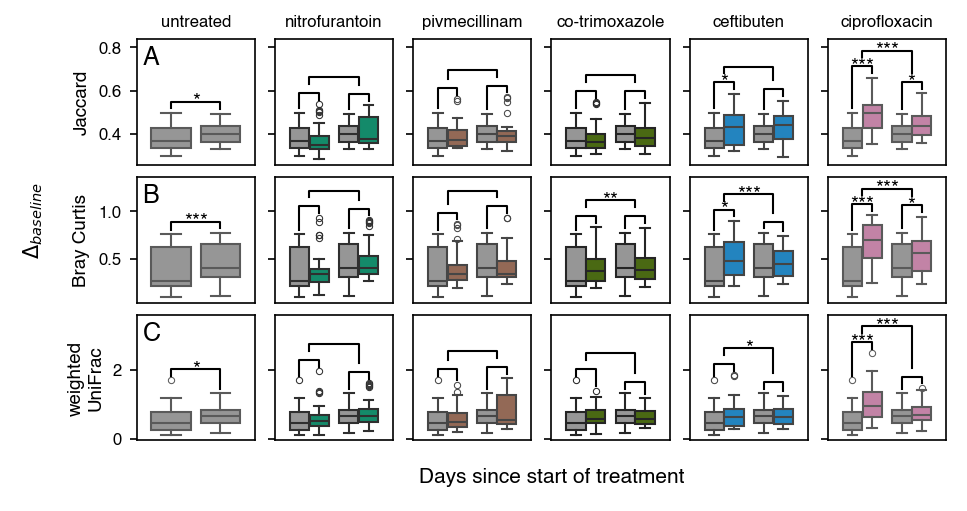

In [29]:
sub_beta = ['jaccard',
            'braycurtis',
            'weighted_unifrac'
            ]
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(6.25, 3.25), facecolor='None')
[[figy, fig], [_, figx]] = figa.subfigures(2, 2, height_ratios=[3, 0.25], width_ratios=[0.25, 6])

gs = fig.add_gridspec(3, 6, 
                      height_ratios=[1, 1, 1],
                      width_ratios=[1, 1, 1, 1, 1, 1],
                      )

for row, metric in enumerate(sub_beta):
    abx_axes = []
    for abx in np.arange(6):
        if abx == 0:
            ax1 = fig.add_subplot(gs[row, abx])
        else:
            ax1 = fig.add_subplot(gs[row, abx], sharex=ax1, sharey=ax1)
    
        ap._build_beta_boxplot(ax1, metric, abx, meta_r)
        ax1.xaxis.set_tick_params(bottom=True, labelbottom=(row == 4), top=False, 
                                  labeltop=False, length=0, labelsize=8)
        ax1.yaxis.set_tick_params(left=True, labelleft=(abx == 0), labelsize=8, 
                                  right=False, labelright=False)
        abx_axes.append(ax1)
    ylims = ax1.get_ylim()
    yscale = np.diff(ylims)[0]
    for abx, abx_ax in enumerate(abx_axes):
        if row == 0:
            abx_ax.set_title(abx_order[abx], size=8)
        lines, plabs = ap._build_lines_abx(ylims, abx, metric, tops, 
                                           period_pvals=period_pvals, 
                                           inter_pvals=inter_pvals)
        for ll, p_ in zip(*(lines, plabs)):
            abx_ax.plot(*ll, color='k', linestyle='-', linewidth=1)
            abx_ax.text(x=np.mean(ll[0]), y=np.max(ll[1]), s=p_, 
                        ha='center', va='center', size=10)
    abx_ax.set_ylim(abx_ax.get_ylim()[0], 
                    abx_ax.get_ylim()[1] + 0.05 * np.diff(abx_ax.get_ylim())[0])
    abx_axes[0].text(abx_ax.get_xlim()[0] + 0.05 * np.diff(abx_ax.get_xlim()), 
                     abx_ax.get_ylim()[1] - 0.05 * np.diff(abx_ax.get_ylim()),
                    'ABCDEFG'[row], 
                    ha='left', va='top', size=12)
ap._add_labelfig(figy, '$\\Delta_{baseline}$', 
                  rotation=90, 
                  position=(0.05, 0.1, 0.9, 0.85))
ap._add_labelfig(figx, 'Days since start of treatment', 
                  position=(0.1, 0, 0.90, 1))
figa.savefig('output/figures/figure_s9_beta_boxes.png', dpi=600, facecolor='None')
figa.savefig('output/figures/figure_s9_beta_boxes.pdf', dpi=600, facecolor='None')

Even though I really liked the combined forest plot, we'll go to a sperate forest plot to accomidate reviewer 2.

In [30]:
beta_wrap = ['jaccard', 'braycurtis',
             'unweighted_unifrac', 'weighted_unifrac']

We'll start by extracting the dat awe need for the forest plot

In [31]:
# Pulls out the susbet of models we're interested in
period_idx = period_params.index.to_frame()
period_keep = \
    period_idx['model'].isin(['model 2']) | \
    period_idx[['model', 'rs_slope']].isin(['model 3', 0, '0']).all(axis=1)
sub_plotter = period_params.loc[period_keep].copy() 
sub_plotter.reset_index(inplace=True)

# Calculates the width of the data and strings
sub_plotter[['params', 'ci_lo', 'ci_hi']] = \
    sub_plotter[['params', 'ci_lo', 'ci_hi']] / 10
sub_plotter['width'] = sub_plotter['ci_hi'] - sub_plotter['params']
sub_plotter['tidy'] = sub_plotter[['params', 'ci_lo', 'ci_hi']].apply(
    lambda x: '{params:>4.2f} ({ci_lo:>4.2f}, {ci_hi:>4.2f})'.format(**x), axis=1)

# Masks the ref values to be 0 (the reference)
unt_mask = sub_plotter['abx_code'] == sub_plotter['ref_value']
sub_plotter['tidy'] = sub_plotter['tidy'].mask(unt_mask, '0 (ref)')
sub_plotter['p_value'] = sub_plotter['p_value'].mask(unt_mask, 1)
sub_plotter['width'] = sub_plotter['width'].mask(unt_mask, np.nan)
sub_plotter['params'] = sub_plotter['params'].mask(unt_mask, 0)

# Sets up antibiotic related coloring, etc
sub_plotter['color'] = sub_plotter['abx_code'].replace(abx_colors)
sub_plotter['fc'] = sub_plotter['color'].mask(sub_plotter['p_value'] >= 0.05, 'w')
sub_plotter['marker'] = \
    sub_plotter['model'].replace({'model 2': 's', 'model 3': 'o'}).mask(
        sub_plotter['rs_slope'].isin(['1', 1]), 'D')

# Calculates the y-position to group the antibiotics together
sub_plotter['y2'] = \
    2.25 * (5 - sub_plotter['abx_code'].astype(int)) + \
    0.5 * sub_plotter['period'].replace({2: -1}) + \
    0.2 - 0.4 * (sub_plotter[['model', 'rs_slope']].isin(['model 3', '1', 1]).any(axis=1)) + \
    0

sub_plotter['metric'] = pd.Categorical(sub_plotter['metric'], categories=beta_wrap, ordered=True)
sub_plotter.set_index(['metric', 'model', 'rs_slope', 'period', 'abx_code'],
                      inplace=True)
sub_plotter.sort_index(inplace=True)

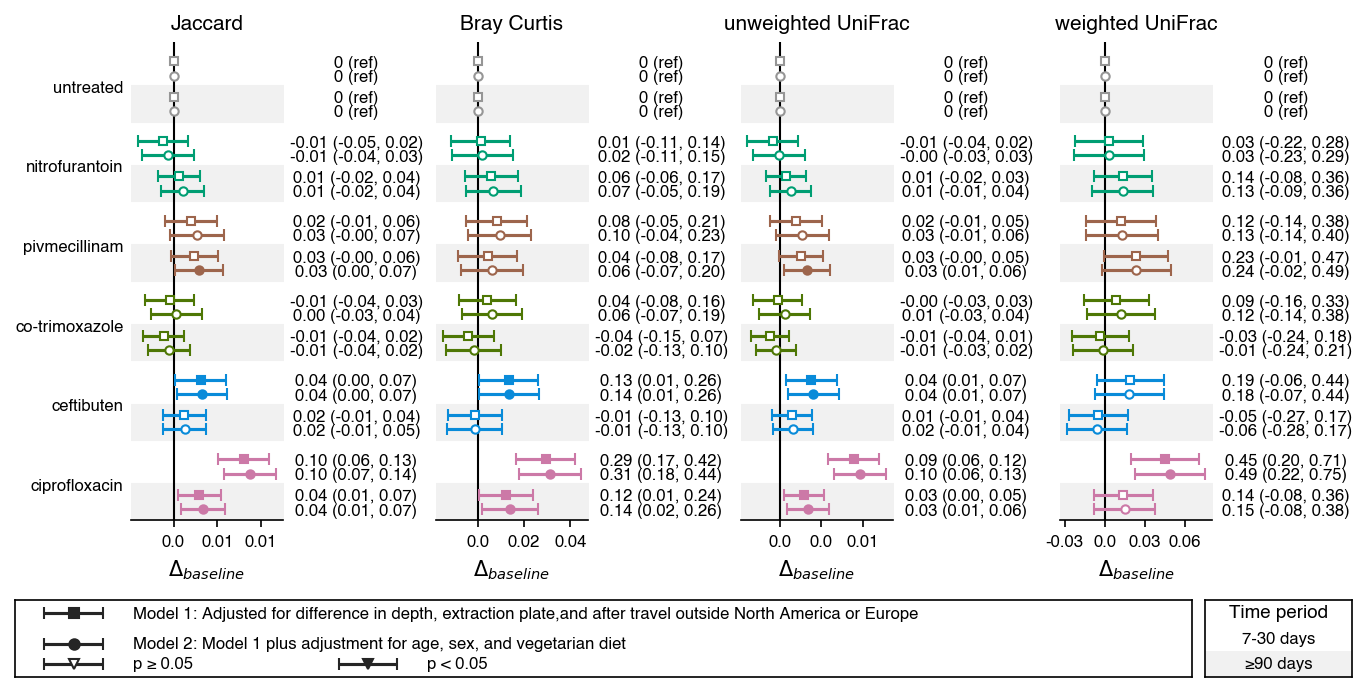

In [32]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(9, 4.5), facecolor='None')
fig, figl = figa.subfigures(2, 1, height_ratios=[3.9, 0.6], facecolor='None')
gs = fig.add_gridspec(1, 4)
for i, (metric, mdf) in enumerate(sub_plotter.xs(0, level='rs_slope').groupby('metric')):
    axy = int(np.floor(i / 4))
    axx = i - 4 * axy
    ax = fig.add_subplot(gs[axy, axx])
    ap._wrap_striped_forest(ax, metric, mdf, axx == 0)
    ax.set_title(clean_metrics.get(metric, metric.title()).replace('\n', ' '), size=10)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: np.round(x/10, 2)))
ap._wrap_striped_legend_model(figl)

**Figure R5. Effect of antibiotic treatment and time since intervention on beta diversity.** Forests slowing the effect of antibiotic treatment on the distance or dissimilarity from baseline in the early (7-30 days; white background) and late (≥ 90 days, gray background). Effects are compared to the untreated group for the period, indicated by shading. Metrics are arranged to weight by abundance: presence/absence (left), compositional (middle), and weighted (right) with non-phylogenetic metrics on top and phylogenetic metrics on the bottom. Color indicates the antibiotic, marker indicate the model. 

In [33]:
sub_plotter2 = sub_plotter.xs('model 2', level='model')
sub_plotter2 = sub_plotter2.xs(0, level='rs_slope').copy()
sub_plotter2['y'] = \
    5 - (sub_plotter2.index.to_frame()['abx_code'].astype(float) + \
        0.25 * sub_plotter2.index.to_frame()['period'].replace({1: 1, 2: -1}))

In [34]:
# sub_plotter2

(0.0, 1.0)

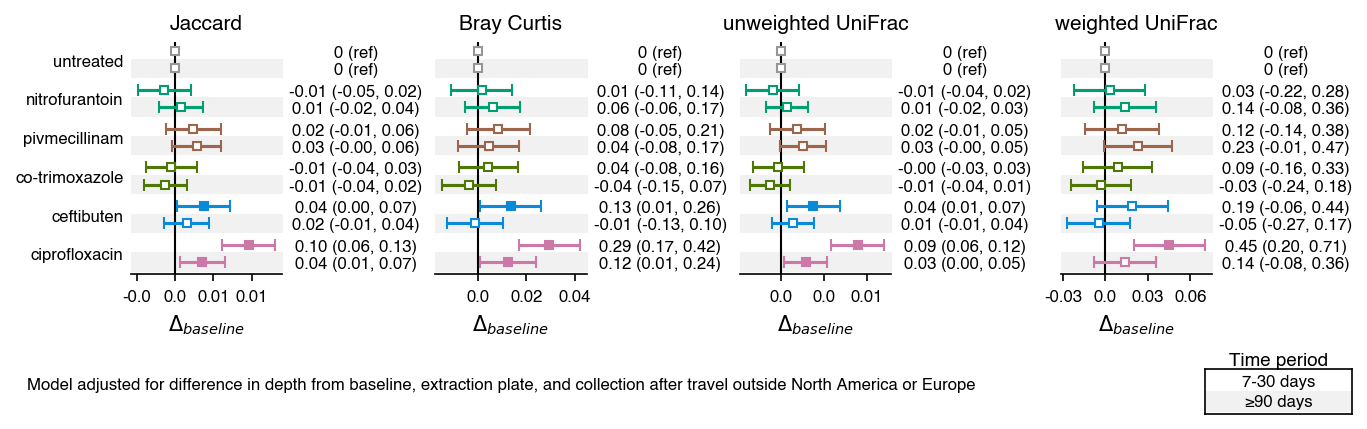

In [35]:
figa = plt.figure(dpi=150, constrained_layout=True, figsize=(9, 2.75), facecolor='None')
fig, figl = figa.subfigures(2, 1, height_ratios=[2.25, 0.5], facecolor='None')
gs = fig.add_gridspec(1, 4)
for i, (metric, mdf) in enumerate(sub_plotter2.groupby('metric', sort=False)):
    ax0 = fig.add_subplot(gs[0, i])
    ap._wrap_striped_forest(ax0, metric, mdf, i == 0)
    ax0.set_title(clean_metrics.get(metric, metric.title()).replace('\n', ' '), size=10)
    ax0.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: np.round(x/10, 2)))

gsl = figl.add_gridspec(1, 2, width_ratios=[8, 1])
axl1 = figl.add_subplot(gsl[0], facecolor='None')
model_text = ('Model adjusted for difference in depth from baseline, '
              'extraction plate, and collection after travel outside North '
              'America or Europe')
axl1.set_xlim(0, 1)
axl1.text(0.01, 0.85, model_text, ha='left', va='center', size=8)
axl1.xaxis.set_tick_params(**hide_axes)
axl1.yaxis.set_tick_params(**hide_axes)
sn.despine(ax=axl1, left=True, right=True, top=True, bottom=True)
axl2 = figl.add_subplot(gsl[1], facecolor='None', sharey=axl1)
axl2.xaxis.set_tick_params(**hide_axes)
axl2.yaxis.set_tick_params(**hide_axes)
axl2.fill_between(x=[0, 1], y1=0.5, y2=1.5, color='w', edgecolor='None')
axl2.fill_between(x=[0, 1], y1=-0.5, y2=0.5, color='#f1f1f1', edgecolor='None')
axl2.text(0.5, 1, '7-30 days', ha='center', va='center', size=8)
axl2.text(0.5, 0, '≥90 days', ha='center', va='center', size=8)
axl2.text(0.5, 2, 'Time period', ha='center', va='center', size=9, weight='bold')
axl2.set_xlim(0, 1)


In [36]:
figa.savefig('output/figures/figure_s10_beta_forest.png', dpi=600, facecolor='None')
figa.savefig('output/figures/figure_s10_beta_forest.pdf', dpi=600, facecolor='None')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


## Posthoc

In [37]:
# def build_ph_tidy(x):
#     est = -(x['estimate'])
#     se = x['SE']
#     return f'{est:>4.3f}±{se:>4.3f}'

def _tidy_p(x):
    if x >= 0.01:
        return f'p{x:1.2f}'
    elif x >= 0.001:
        return f'p{x:1.3f}'
    elif x < 0.001:
        return 'p<0.001'
    else:
        return f'{x:1.0E}'

# sub_posthoc = \
#     beta_contrast_r.xs('model2', level='model').xs('re', level='rs').copy()
# sub_posthoc = sub_posthoc.xs('.', level='abx_code2').copy()
# sub_posthoc['tidy'] = sub_posthoc.apply(build_ph_tidy, axis=1)
# sub_posthoc['p_tidy'] = sub_posthoc['p.value'].apply(_tidy_p)

In [38]:
ph_dir = 'final-data/06.beta-diveristy/post-hoc-fits/'
os.makedirs(ph_dir, exist_ok=True)
meta_r.to_csv(f'{ph_dir}/beta_traces.tsv', sep='\t')

In [39]:
%%bash
Rscript scripts/emmeans_posthoc/beta_lmer_posthoc.r

There were 50 or more warnings (use warnings() to see the first 50)


In [40]:
beta_expand_r = pd.read_csv(f'{ph_dir}/beta_expanded_est.tsv', 
                            sep='\t', 
                            dtype=str)
beta_expand_r.set_index(['metric', 'model', 'rs', 'abx_code2', 'period'],
                        inplace=True)
beta_expand_r = beta_expand_r.astype(float)

In [41]:
beta_contrast_r = pd.read_csv(f'{ph_dir}/beta_expanded_contrasts.tsv',
                              sep='\t',
                              dtype=str)
beta_contrast_r.set_index(
    ['metric', 'model', 'rs', 'period', 'abx_code2', 'c1', 'c2'],
    inplace=True)
beta_contrast_r = beta_contrast_r.astype(float)

In [42]:
beta_expand_r2 = beta_expand_r.xs('model2', level='model').xs('re', level='rs')
beta_expand_r2.rename(columns={c: c.replace(".", '_').lower()
                               for c in beta_expand_r2.columns},
                      inplace=True)
beta_expand_r2['tidy'] = beta_expand_r2.apply(
    lambda x: '{beta:1.2f} ({lower_cl:1.2f}, {upper_cl:1.2f})'.format(**x), 
    axis=1)
beta_expand_tidy = beta_expand_r2['tidy']
beta_expand_tidy.index = beta_expand_tidy.index.reorder_levels(['metric', 'period', 'abx_code2'])

In [43]:
beta_contrast_r2 = beta_contrast_r.copy()
beta_contrast_r2 = beta_contrast_r2.xs('model2', level='model').xs('re', level='rs')
beta_contrast_r2.rename(columns={c: c.replace('.', '_').lower() 
                                 for c in beta_contrast_r2.columns},
                        inplace=True)
beta_contrast_r2['estimate'] = beta_contrast_r2['estimate'] * -1
beta_contrast_r2['width'] = \
    beta_contrast_r2['se'] * \
    scipy.stats.t.ppf(1-0.05/2, beta_contrast_r2['df'] - 1)
beta_contrast_r2['ci_lo'] = beta_contrast_r2['estimate'] - beta_contrast_r2['width']
beta_contrast_r2['ci_hi'] = beta_contrast_r2['estimate'] + beta_contrast_r2['width']

beta_contrast_r2['tidy'] = beta_contrast_r2.apply(
    lambda x: '{estimate:1.2f} ({ci_lo:1.2f}, {ci_hi:1.2f})'.format(**x),
    axis=1)
beta_contrast_r2['p_tidy'] = beta_contrast_r2['p_value'].apply(_tidy_p)

In [44]:
abx_comp = beta_contrast_r2.xs('.', level='abx_code2')[['tidy', 'p_tidy']].copy()
abx_comp.reset_index(level=['c2'], inplace=True)
abx_comp['abx1_est'] = beta_expand_tidy.loc[abx_comp.index].values
abx_comp.reset_index(level=['c1'], inplace=True)
abx_comp.set_index('c2', append=True, inplace=True)
abx_comp['abx2_est'] = beta_expand_tidy.loc[abx_comp.index].values
abx_comp.set_index('c1', inplace=True, append=True)
abx_comp.index = \
    abx_comp.index.reorder_levels(['metric', 'period', 'c1', 'c2'])
abx_comp.sort_index(inplace=True)
abx_comp.rename(index=abx_names, level='c1', inplace=True)
abx_comp.rename(index=abx_names, level='c2', inplace=True)
abx_comp.rename({'1': '7-30 days', '2': '≥90 days'}, inplace=True, level='period')
abx_comp = abx_comp[['abx1_est', 'abx2_est', 'tidy', 'p_tidy']]

In [45]:
HTML(abx_comp.to_html())

In [46]:
abx_comp.to_csv('output/tables/table_s4_beta_posthoc.tsv',
                sep='\t')